<a href="https://colab.research.google.com/github/rgonzalezp-ucsc/Ciencia-de-Datos_UCSC_Rodrigo_G/blob/main/S5_Notebook_CDD_Final_GONZALEZ_RODRIGO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio 5 — Comunicación, anonimización y sesgo
**Ciencia de Datos · Semana 5 · Advance UCSC**

| | |
|---|---|
| **Resultado de aprendizaje** | RA4 (foco) · RA5 (cierre) · RA3 (integración) |
| **Duración estimada** | 1 h asincrónica + 0,5 h de trabajo autónomo |
| **Insumos** | `conjunto_minado_RG.csv` (semana 4) y `S5_Dataset_Personales_Sintetico_CDD.csv` |
| **Producto** | Las visualizaciones del informe + la ficha ético-legal cerrada |
| **Estudiante** | _Rodrigo I. González P._ |

---

Última semana. Dos trabajos distintos:

1. **Convertir tus gráficos exploratorios en explicativos.** Los de la semana 3 eran para ti; estos son para alguien que no conoce tus datos y tiene diez segundos.
2. **Cerrar la dimensión ética**: anonimizar un conjunto con datos personales y detectar sesgo.

Lo que produzcas aquí va directo a la **Entrega Final**: las visualizaciones a la Sección B, la ficha a la Sección C.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RUTA = ''
SEMILLA = 20265
np.random.seed(SEMILLA)
plt.rcParams.update({'figure.figsize': (9, 4.5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('Listo')

Listo


---
## Parte 1 · De exploratorio a explicativo

Son dos géneros distintos, y confundirlos es el error más común al comunicar datos.

| | Gráfico **exploratorio** | Gráfico **explicativo** |
|---|---|---|
| Para quién | Para ti, mientras analizas | Para alguien que no conoce los datos |
| Cuántos haces | Docenas | Dos o tres |
| Cuánto tiempo se le dedica | El que haga falta | Diez segundos |
| Qué lleva | Todo lo que quieras ver | Una sola idea, destacada |
| Título | «ventas_por_comuna» | «Coronel concentra el 38 % de las ventas» |

> **El título de un gráfico explicativo no nombra las variables: enuncia el hallazgo.** Si alguien lee solo el título, ya debería llevarse la conclusión.

In [3]:
# Trabajamos con el conjunto guía para el ejemplo; después lo harás con el tuyo
p = pd.read_csv(RUTA + 'S5_Dataset_Personales_Sintetico_CDD.csv', sep=';')
print('Forma:', p.shape)
p[['comuna', 'nivel_educacional', 'ingreso_mensual_miles', 'aprobado']].head()
#p.iloc[:5, :15]  muestra 5 filas y 15 columnas

Forma: (420, 15)


,comuna,nivel_educacional,ingreso_mensual_miles,aprobado
0,Coronel,Universitaria incompleta,618,Sí
1,Lota,Técnica,914,No
2,Concepción,Universitaria incompleta,482,Sí
3,Lota,Media completa,642,Sí
4,Tomé,Media completa,462,Sí


### 1.1 El mismo dato, dos gráficos

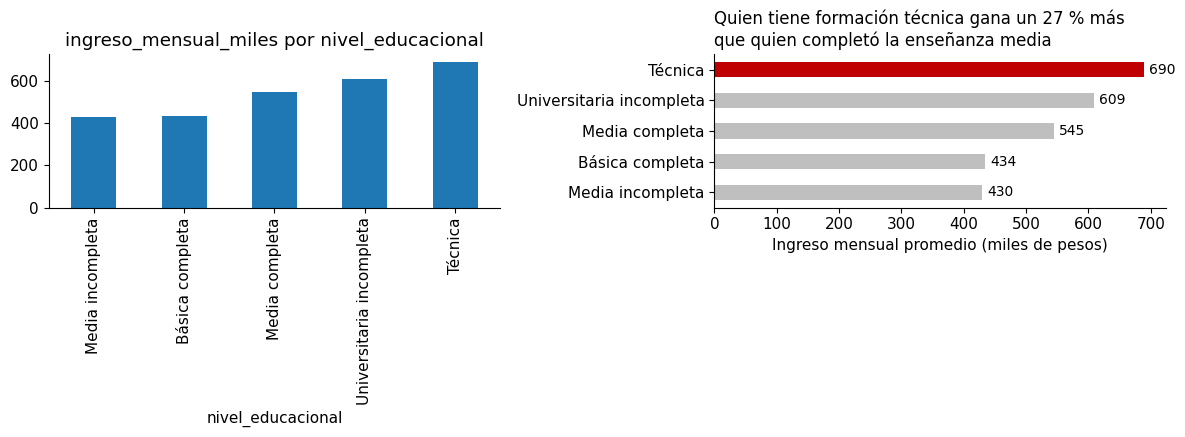

Verificación del titular: 26.6%


In [4]:
ingreso = p.groupby('nivel_educacional')['ingreso_mensual_miles'].mean().sort_values()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# --- EXPLORATORIO: rápido, sin adornos, para mirarlo tú
ingreso.plot.bar(ax=ax[0])
ax[0].set_title('ingreso_mensual_miles por nivel_educacional')

# --- EXPLICATIVO: una idea, destacada
colores = ['#BFBFBF'] * len(ingreso)
colores[-1] = '#C00000'
ingreso.plot.barh(ax=ax[1], color=colores)
ax[1].set_title('Quien tiene formación técnica gana un 27 % más\nque quien completó la enseñanza media', loc='left', fontsize=12)
ax[1].set_xlabel('Ingreso mensual promedio (miles de pesos)')
ax[1].set_ylabel('')
for i, v in enumerate(ingreso):
    ax[1].text(v + 8, i, f'{v:,.0f}'.replace(',', '.'), va='center', fontsize=10)
plt.tight_layout(); plt.show()

print(f"Verificación del titular: {ingreso['Técnica']/ingreso['Media completa']-1:.1%}")

Cuatro cambios convierten uno en otro, y ninguno es decorativo:

1. **Barras horizontales**: las etiquetas largas se leen sin girar la cabeza.
2. **Gris salvo lo que importa**: el color dirige la mirada. Si todo es de colores, nada destaca.
3. **El valor sobre la barra**: quien quiera el número exacto no tiene que estimarlo contra el eje.
4. **Título que enuncia el hallazgo**, con la cifra verificada en la celda.

> **Verifica siempre el número que pones en el título.** Es el error más embarazoso posible: un titular que el propio gráfico desmiente.

### 1.2 Elegir el gráfico según la pregunta

| Si la pregunta es… | El gráfico es… | Evita |
|---|---|---|
| ¿Cuánto hay de cada categoría? | Barras (horizontales si son muchas o largas) | Torta con más de 4 porciones |
| ¿Cómo cambió en el tiempo? | Línea | Barras, que sugieren categorías independientes |
| ¿Cómo se distribuye una variable? | Histograma o caja | Solo el promedio |
| ¿Se relacionan dos variables? | Dispersión | Dos líneas con ejes distintos |
| ¿Cómo se compone un total? | Barras apiladas | Torta anidada, ilegible |

### ✏️ Actividad 1.1

Toma **dos hallazgos** de tu conjunto (semanas 3 y 4) y construye su versión explicativa. Para cada uno: elige el tipo según la pregunta, deja en gris lo secundario, rotula los valores y escribe un título que enuncie el hallazgo con su cifra.

Estos dos gráficos van al informe final.

In [5]:
mio = pd.read_csv(RUTA + 'conjunto_minado_RG.csv', sep=';')

print("Dimensiones del conjunto:", mio.shape)

print("\nColumnas disponibles:")
print(mio.columns.tolist())

print("\nPrimeros 5 registros:")
display(mio.head())

print("\nInformación de los datos:")
mio.info()


Dimensiones del conjunto: (731, 21)

Columnas disponibles:
['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt', 'anio', 'mes', 'dia_semana', 'grupo', 'distancia']

Primeros 5 registros:


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,...,hum,windspeed,casual,registered,cnt,anio,mes,dia_semana,grupo,distancia
0,1.0,2011-01-01,1.0,0.0,1.0,0.0,6.0,0.0,2.0,0.344167,...,0.805833,0.160446,331.0,654.0,985.0,2011,1,5,2,1.577111
1,2.0,2011-01-02,1.0,0.0,1.0,0.0,0.0,0.0,2.0,0.363478,...,0.696087,0.248539,131.0,670.0,801.0,2011,1,6,2,1.895873
2,3.0,2011-01-03,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.196364,...,0.437273,0.248309,120.0,1229.0,1349.0,2011,1,0,1,1.213012
3,4.0,2011-01-04,1.0,0.0,1.0,0.0,2.0,1.0,1.0,0.200000,...,0.590435,0.160296,108.0,1454.0,1562.0,2011,1,1,1,1.626018
4,5.0,2011-01-05,1.0,0.0,1.0,0.0,3.0,1.0,1.0,0.226957,...,0.436957,0.186900,82.0,1518.0,1600.0,2011,1,2,1,1.306484



Información de los datos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 21 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    float64
 1   dteday      731 non-null    object 
 2   season      731 non-null    float64
 3   yr          731 non-null    float64
 4   mnth        731 non-null    float64
 5   holiday     731 non-null    float64
 6   weekday     731 non-null    float64
 7   workingday  731 non-null    float64
 8   weathersit  731 non-null    float64
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    float64
 14  registered  731 non-null    float64
 15  cnt         731 non-null    float64
 16  anio        731 non-null    int64  
 17  mes         731 non-null    int64  
 18  dia_semana  731 non-null    int64  
 19  gr

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Cargar nuestro conjunto de datos
mio = pd.read_csv(RUTA + 'conjunto_minado_RG.csv', sep=';')

print("Dimensiones:", mio.shape)

# Revisar los grupos encontrados
print("\nCantidad de registros por grupo:")
print(mio['grupo'].value_counts().sort_index())

# Resumen de alquileres
print("\nEstadísticas de alquileres:")
print(mio['cnt'].describe())

# Promedio de alquileres por mes
print("\nAlquileres promedio por mes:")
print(mio.groupby('mes')['cnt'].mean().round(2))

# Promedio de alquileres según condición climática
print("\nAlquileres por condición climática:")
print(mio.groupby('weathersit')['cnt'].mean().round(2))

Dimensiones: (731, 21)

Cantidad de registros por grupo:
grupo
0    247
1    233
2    251
Name: count, dtype: int64

Estadísticas de alquileres:
count     731.000000
mean     4504.348837
std      1937.211452
min        22.000000
25%      3152.000000
50%      4548.000000
75%      5956.000000
max      8714.000000
Name: cnt, dtype: float64

Alquileres promedio por mes:
mes
1     2176.34
2     2655.30
3     3692.26
4     4484.90
5     5349.77
6     5772.37
7     5563.68
8     5664.42
9     5766.52
10    5199.23
11    4247.18
12    3403.81
Name: cnt, dtype: float64

Alquileres por condición climática:
weathersit
1.0    4876.79
2.0    4035.86
3.0    1803.29
Name: cnt, dtype: float64


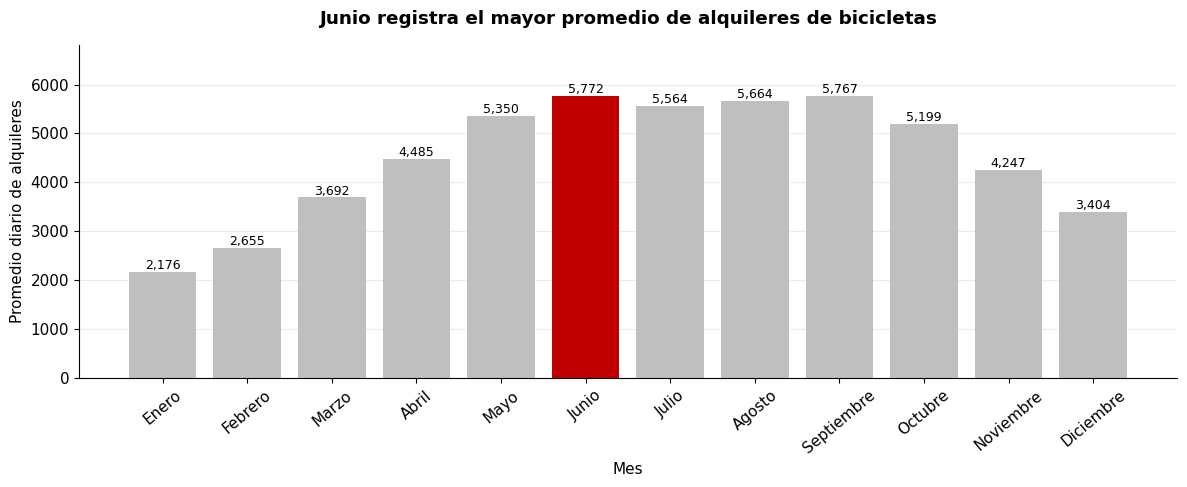

Mayor demanda: Junio
Promedio: 5772.37


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Cargar nuestro conjunto de datos
mio = pd.read_csv(RUTA + 'conjunto_minado_RG.csv', sep=';')

# Configuración visual
plt.rcParams.update({
    'figure.figsize': (10, 5),
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False
})

# ==========================================
# GRÁFICO 1: DEMANDA MENSUAL DE BICICLETAS
# ==========================================

mensual = mio.groupby('mes')['cnt'].mean()
mensual = mensual.reindex(range(1, 13))

nombres_meses = [
    'Enero', 'Febrero', 'Marzo', 'Abril',
    'Mayo', 'Junio', 'Julio', 'Agosto',
    'Septiembre', 'Octubre', 'Noviembre', 'Diciembre'
]

fig, ax = plt.subplots(figsize=(12, 5))

# Destacar el mes con mayor demanda
colores = ['#BFBFBF'] * 12
colores[mensual.values.argmax()] = '#C00000'

barras = ax.bar(
    nombres_meses,
    mensual.values,
    color=colores
)

ax.set_title(
    'Junio registra el mayor promedio de alquileres de bicicletas',
    fontweight='bold',
    pad=15
)

ax.set_ylabel('Promedio diario de alquileres')
ax.set_xlabel('Mes')
ax.set_ylim(0, mensual.max() * 1.18)

for barra, valor in zip(barras, mensual.values):
    ax.text(
        barra.get_x() + barra.get_width()/2,
        valor + 60,
        f'{valor:,.0f}',
        ha='center',
        fontsize=9
    )

ax.tick_params(axis='x', rotation=40)
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    'grafico_1_demanda_mensual.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Mayor demanda:", nombres_meses[mensual.values.argmax()])
print("Promedio:", round(mensual.max(), 2))

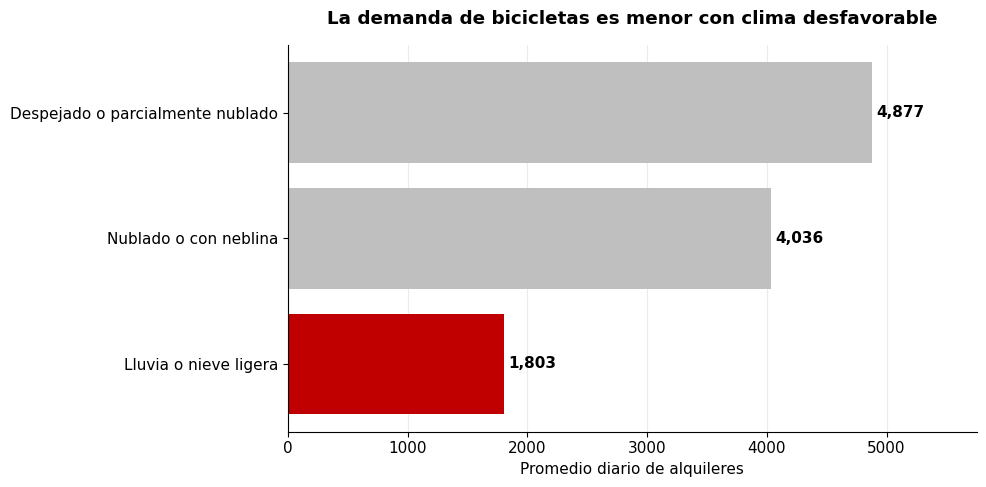

Promedios según condición climática:
weathersit
3.0    1803.29
2.0    4035.86
1.0    4876.79
Name: cnt, dtype: float64


In [8]:
# ==========================================
# GRÁFICO 2: DEMANDA SEGÚN CONDICIONES CLIMÁTICAS
# ==========================================

clima = mio.groupby('weathersit')['cnt'].mean().sort_values()

etiquetas = {
    1.0: 'Despejado o parcialmente nublado',
    2.0: 'Nublado o con neblina',
    3.0: 'Lluvia o nieve ligera'
}

nombres = [etiquetas[x] for x in clima.index]

colores = [
    '#C00000' if x == 3 else '#BFBFBF'
    for x in clima.index
]

fig, ax = plt.subplots(figsize=(10, 5))

barras = ax.barh(
    nombres,
    clima.values,
    color=colores
)

ax.set_title(
    'La demanda de bicicletas es menor con clima desfavorable',
    fontweight='bold',
    pad=15
)

ax.set_xlabel('Promedio diario de alquileres')
ax.set_xlim(0, clima.max() * 1.18)

for barra, valor in zip(barras, clima.values):
    ax.text(
        valor + 35,
        barra.get_y() + barra.get_height()/2,
        f'{valor:,.0f}',
        va='center',
        fontweight='bold'
    )

ax.grid(axis='x', alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    'grafico_2_demanda_climatica.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Promedios según condición climática:")
print(clima.round(2))

---
## Parte 2 · Representación honesta

Los dos gráficos de `S5_Graficos_Prensa_CDD.pdf` no contienen ningún dato falso. Vamos a reproducir sus distorsiones para entender exactamente qué hacen.

### 2.1 El eje truncado

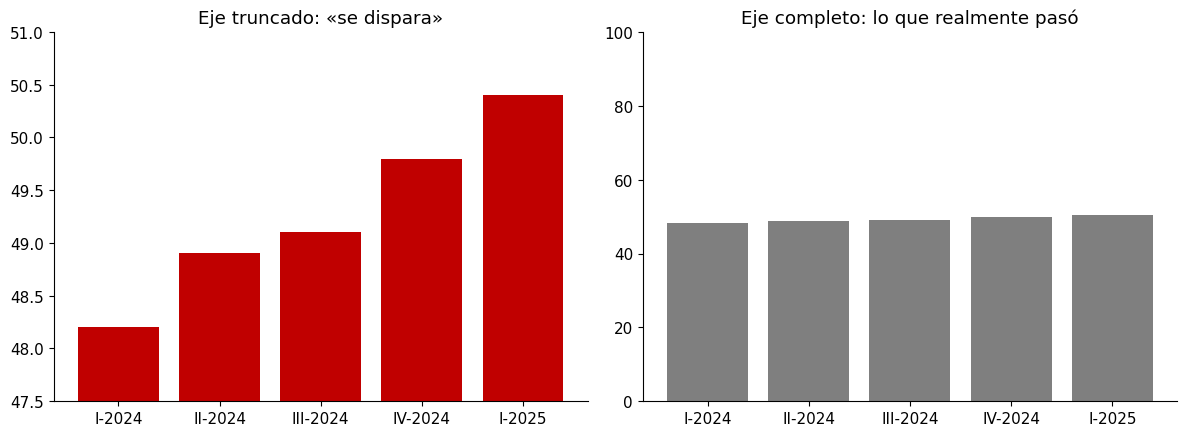

Variación real: 2.2 puntos = 4.6 %


In [9]:
trimestres = ['I-2024', 'II-2024', 'III-2024', 'IV-2024', 'I-2025']
satisfaccion = [48.2, 48.9, 49.1, 49.8, 50.4]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].bar(trimestres, satisfaccion, color='#C00000')
ax[0].set_ylim(47.5, 51)
ax[0].set_title('Eje truncado: «se dispara»')

ax[1].bar(trimestres, satisfaccion, color='#7F7F7F')
ax[1].set_ylim(0, 100)
ax[1].set_title('Eje completo: lo que realmente pasó')
plt.tight_layout(); plt.show()

print(f'Variación real: {satisfaccion[-1] - satisfaccion[0]:.1f} puntos = '
      f'{(satisfaccion[-1]/satisfaccion[0] - 1)*100:.1f} %')

El mismo dato. A la izquierda parece una explosión; a la derecha, una línea casi plana. El aumento real es de **2,2 puntos, un 4,6 %**.

> **¿Truncar el eje es siempre deshonesto?** No. En una serie que oscila entre 48 y 51 nunca, mostrar desde cero puede ocultar variación relevante. La regla practicable es: **en gráficos de barras, el eje parte en cero** —porque la barra comunica magnitud por su largo—; **en gráficos de línea puedes truncar**, siempre que lo señales de forma visible.

### 2.2 Magnitudes brutas entre unidades de distinto tamaño

Esta es la misma trampa de la semana 3, ahora en formato gráfico.

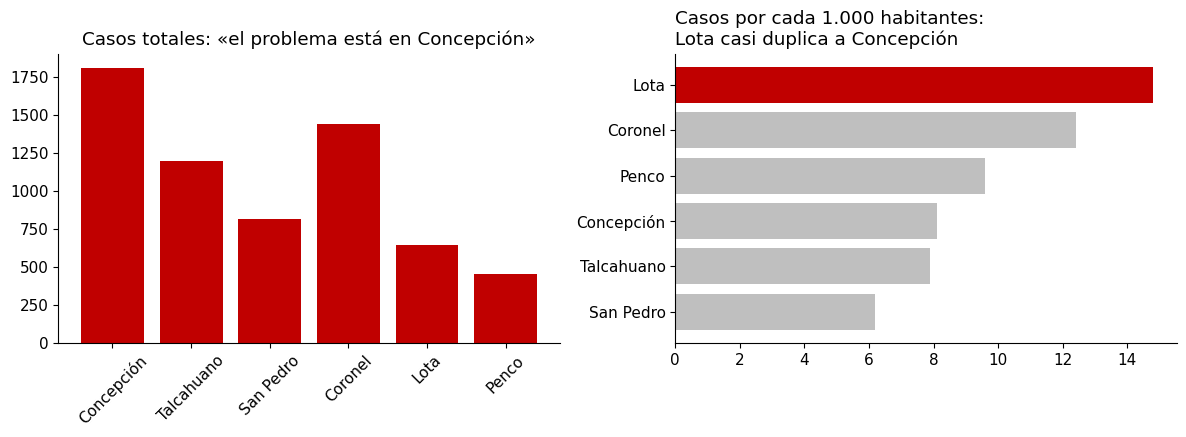

Lota             644 casos ·  14.8 por mil habitantes
Coronel         1441 casos ·  12.4 por mil habitantes
Penco            452 casos ·   9.6 por mil habitantes
Concepción      1810 casos ·   8.1 por mil habitantes
Talcahuano      1198 casos ·   7.9 por mil habitantes
San Pedro        817 casos ·   6.2 por mil habitantes


In [ ]:
comunas = ['Concepción', 'Talcahuano', 'San Pedro', 'Coronel', 'Lota', 'Penco']
poblacion = [223574, 151749, 131808, 116262, 43535, 47105]
tasa = [8.1, 7.9, 6.2, 12.4, 14.8, 9.6]          # por cada 1.000 habitantes
#La tasa se calcula dividiendo los casos por la población y luego multiplicando por 1000

casos = [int(pob * t / 1000) for pob, t in zip(poblacion, tasa)]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].bar(comunas, casos, color='#C00000')
ax[0].set_title('Casos totales: «el problema está en Concepción»')
ax[0].tick_params(axis='x', rotation=45)

orden = np.argsort(tasa)
col = ['#BFBFBF'] * 6
col[list(orden).index(4)] = '#C00000'
ax[1].barh([comunas[i] for i in orden], [tasa[i] for i in orden],
           color=[col[i] for i in range(6)])
ax[1].set_title('Casos por cada 1.000 habitantes:\nLota casi duplica a Concepción', loc='left')
plt.tight_layout(); plt.show()

for c, t, k in sorted(zip(comunas, tasa, casos), key=lambda x: -x[1]):
    print(f'{c:14s} {k:5d} casos · {t:5.1f} por mil habitantes')

A la izquierda, Concepción encabeza. A la derecha, **Concepción es de las más bajas** y Lota casi la duplica. Los datos son los mismos.

> **Regla:** si las unidades que comparas tienen tamaños distintos, normaliza antes de graficar. Casos por mil habitantes, ventas por metro cuadrado, accidentes por kilómetro recorrido.

### ✏️ Actividad 2.1

Revisa tus dos gráficos de la actividad 1.1 y responde:

- ¿Algún eje está truncado? Si lo está, ¿se justifica y está señalado?
- ¿Comparas unidades de distinto tamaño sin normalizar?
- ¿El título afirma algo que el gráfico no muestra?
- ¿Omites algún período o categoría que cambiaría la lectura?

### Tu autorrevisión

**1. ¿Algún eje está truncado? Si lo está, ¿se justifica y está señalado?**

No. Ambos gráficos comienzan en cero en sus respectivos ejes de valores. El primero representa el promedio diario de alquileres por mes y el segundo compara el promedio de alquileres según las condiciones climáticas. Esto permite visualizar las diferencias sin exagerar las magnitudes.

**2. ¿Comparas unidades de distinto tamaño sin normalizar?**

No. Ambos gráficos utilizan la misma unidad de medida: el promedio diario de alquileres de bicicletas. No estamos comparando cantidades con escalas o unidades diferentes, por lo que no es necesario aplicar una normalización adicional.

**3. ¿El título afirma algo que el gráfico no muestra?**

No. Los títulos representan los resultados observados en los datos. El primer gráfico muestra que junio registra el mayor promedio mensual de alquileres, con 5.772 aproximadamente. El segundo muestra que las condiciones de lluvia o nieve ligera presentan el menor promedio, con 1.803 alquileres diarios. Los títulos resumen los hallazgos sin atribuir relaciones de causalidad.

**4. ¿Omites algún período o categoría que cambiaría la lectura?**

No se eliminaron categorías de los datos utilizados. Sin embargo, el primer gráfico agrupa los registros de 2011 y 2012 por mes, por lo que no permite observar las diferencias entre ambos años. El segundo considera las tres condiciones climáticas presentes en nuestro conjunto de datos. Esta agrupación debe tenerse en cuenta al interpretar los resultados.

---
## Parte 3 · Anonimización

Trabajamos sobre `S5_Dataset_Personales_Sintetico_CDD.csv`: 420 participantes de un programa municipal de capacitación.

⚠️ **Los datos son sintéticos**: nombres, RUT y direcciones fueron generados artificialmente para este curso. Los RUT usan un rango no asignado a personas naturales. **No corresponden a nadie real.**

In [10]:
p = pd.read_csv(RUTA + 'S5_Dataset_Personales_Sintetico_CDD.csv', sep=';')
print('Forma:', p.shape)
p.head(3)

Forma: (420, 15)


,participante_id,nombre_completo,rut,email,fecha_nacimiento,sexo,comuna,direccion,ocupacion,nivel_educacional,situacion_laboral,ingreso_mensual_miles,programa,asistencia_pct,aprobado
0,P0001,Florencia Pérez Araya,93.939.245-8,florencia.pérez73@correo.cl,1968-07-09,M,Coronel,Prat 786,Panadero,Universitaria incompleta,Inactivo,618,Alfabetización digital,80,Sí
1,P0002,Florencia Silva Valenzuela,91.854.251-6,florencia.silva25@correo.cl,1978-01-21,M,Lota,Maipú 3523,Panadero,Técnica,Ocupado,914,Emprendimiento,59,No
2,P0003,Paula Fuentes Torres,94.822.480-K,paula.fuentes59@correo.cl,1998-03-13,F,Concepción,Barros Arana 1620,Profesor de educación básica,Universitaria incompleta,Desocupado,482,Apresto laboral,82,Sí


### 3.1 Los tres tipos de identificador

| Tipo | Qué es | En este conjunto |
|---|---|---|
| **Identificador directo** | Identifica por sí solo | nombre_completo, rut, email, direccion |
| **Cuasi-identificador** | No identifica solo, pero sí **en combinación** | comuna, sexo, fecha_nacimiento, ocupacion |
| **Atributo sensible** | Lo que no queremos revelar de nadie | ingreso_mensual_miles, situacion_laboral |

El error clásico es creer que basta con borrar la primera fila de la tabla. Vamos a comprobar que no.

### 3.2 Paso 1 · Quitar los identificadores directos

In [11]:
DIRECTOS = ['nombre_completo', 'rut', 'email', 'direccion']
anon = p.drop(columns=DIRECTOS).copy()
#print('Columnas restantes:', list(anon.columns))
print('Columnas restantes:\n' + '\n'.join(anon.columns))
anon.head(3)

Columnas restantes:
participante_id
fecha_nacimiento
sexo
comuna
ocupacion
nivel_educacional
situacion_laboral
ingreso_mensual_miles
programa
asistencia_pct
aprobado


,participante_id,fecha_nacimiento,sexo,comuna,ocupacion,nivel_educacional,situacion_laboral,ingreso_mensual_miles,programa,asistencia_pct,aprobado
0,P0001,1968-07-09,M,Coronel,Panadero,Universitaria incompleta,Inactivo,618,Alfabetización digital,80,Sí
1,P0002,1978-01-21,M,Lota,Panadero,Técnica,Ocupado,914,Emprendimiento,59,No
2,P0003,1998-03-13,F,Concepción,Profesor de educación básica,Universitaria incompleta,Desocupado,482,Apresto laboral,82,Sí


Sin nombre, sin RUT, sin correo y sin dirección. **¿Está anonimizado?**

+++++++
No, el conjunto de datos todavía no está completamente anonimizado. Se eliminaron los identificadores directos, pero permanecen variables que podrían permitir identificar indirectamente a algunos participantes.

**Aunque se eliminaron el nombre, RUT, correo y dirección, todavía están estos datos que pueden facilitar la reidentificación:**\
Variable - Riesgo\
**participante_id** - Puede permitir vincular registros si existe una tabla que relaciona códigos con personas.\
**fecha_nacimiento**	- Permite conocer la edad y puede facilitar la identificación.\
**comuna** -	Reduce el grupo de posibles personas.\
**ocupacion**	- Algunas ocupaciones pueden ser poco frecuentes.\
**sexo**	- Combinado con otras variables, puede facilitar la identificación.

Ejemplo: una persona nacida el 13/03/1998, residente en Concepción, de sexo femenino y profesora de educación básica podría ser identificable al combinar esos atributos con información externa.

### 3.3 Paso 2 · Medir el k-anonimato

El **k-anonimato** mide cuántas personas comparten exactamente la misma combinación de cuasi-identificadores. Si k = 1, esa persona es **única en el conjunto**: quien conozca esos cuatro datos suyos la encuentra sin más.

+++++++

El objetivo de esta actividad es determinar cuántos participantes pueden distinguirse de los demás utilizando una combinación de cuasiidentificadores.

¿Qué es el k-anonimato?
El k-anonimato mide el tamaño mínimo de los grupos de registros que comparten exactamente los mismos cuasiidentificadores.
- k = 1: existe al menos un participante con una combinación única. Mayor riesgo de reidentificación.
- k = 2: cada participante comparte su combinación con al menos otra persona.
- k = 5: cada participante comparte su combinación con al menos otras cuatro personas.
Cuanto mayor sea k, menor será el riesgo de distinguir a una persona mediante esos cuasiidentificadores. Sin embargo, un k alto no garantiza privacidad absoluta.

In [ ]:
QI = ['comuna', 'sexo', 'fecha_nacimiento', 'ocupacion']
grupos = anon.groupby(QI).size()

print(f'Combinaciones distintas : {len(grupos)}')
print(f'Personas con k = 1      : {(grupos == 1).sum()}  '
      f'({(grupos == 1).sum()/len(anon)*100:.1f} % del conjunto)')
print(f'k mínimo                : {grupos.min()}')

Combinaciones distintas : 420
Personas con k = 1      : 420  (100.0 % del conjunto)
k mínimo                : 1


**420 de 420.** Todas las personas son únicas. El conjunto no está anonimizado en absoluto: cualquiera que sepa la comuna, el sexo, la fecha de nacimiento y el oficio de un conocido puede encontrar su ingreso y su situación laboral.

> Esto no es una hipótesis de laboratorio. En 2006 Netflix publicó un conjunto «anonimizado» de calificaciones de películas; investigadores reidentificaron usuarios cruzándolo con IMDb. En 2014, los registros de taxis de Nueva York permitieron rastrear viajes individuales.

++++++\
(IMDb=Internet Movie Database) es una base de datos en línea que contiene información sobre películas, series de televisión, actores, directores y producciones audiovisuales.

### 3.4 Paso 3 · Generalizar

++++++++
En esta actividad se aplica una técnica de anonimización llamada generalización, cuyo objetivo es reducir el nivel de detalle de los cuasiidentificadores para dificultar la identificación de los participantes.

En el paso anterior se utilizaban cuatro cuasiidentificadores: comuna, sexo, fecha de nacimiento y ocupación.

Ahora se reemplaza la fecha exacta por un tramo de edad y se eliminan algunas columnas detalladas.

Convierte la fecha de nacimiento a formato fecha y extrae solamente el año.

Con una instrucción se calcula una edad aproximada y la agrupa en intervalos de diez años.

In [12]:
anon['anio_nacimiento'] = pd.to_datetime(anon['fecha_nacimiento']).dt.year
anon['tramo_edad'] = ((2026 - anon['anio_nacimiento']) // 10 * 10).astype(str) + '-' + \
                     (((2026 - anon['anio_nacimiento']) // 10 * 10) + 9).astype(str)
anon = anon.drop(columns=['fecha_nacimiento', 'anio_nacimiento', 'ocupacion'])

g2 = anon.groupby(['comuna', 'sexo', 'tramo_edad']).size()
print(f'Combinaciones : {len(g2)}')
print(f'Personas k = 1: {(g2 == 1).sum()}')
print(f'k mínimo      : {g2.min()}')

Combinaciones : 97
Personas k = 1: 5
k mínimo      : 1


+++++++
La operación // 10 * 10 obtiene la decena inferior de la edad. Después se suma 9 para determinar el extremo superior.

Se eliminan las columnas originales que contienen información más detallada.

Agrupa los participantes según tres cuasiidentificadores, en lugar de los cuatro utilizados anteriormente.

Resultado

Combinaciones distintas = 97: los participantes se distribuyen en 97 grupos diferentes según comuna, sexo y tramo de edad.

Personas con k = 1 = 5: existen cinco participantes cuya combinación de estos tres atributos no coincide con la de ningún otro participante.

k mínimo = 1: todavía hay grupos con una sola persona. Por lo tanto, el conjunto aún no cumple 2-anonimato (k = 2), significa que cada persona de una base de datos debe compartir la misma combinación de cuasiidentificadores con al menos otra persona..

¿Qué porcentaje representa?
Como el conjunto contiene 420 participantes:
(5/420}*100=1,19%
Esto significa que aproximadamente el 1,2 % de los participantes sigue siendo único según los cuasiidentificadores seleccionados.

De 420 únicos bajamos a 5. Mejor, pero **cinco personas siguen siendo identificables**.

### 3.5 Paso 4 · Generalizar un nivel más

In [13]:
# Las diez comunas pertenecen a la Provincia de Concepción
anon['provincia'] = 'Concepción'
g3 = anon.groupby(['provincia', 'sexo', 'tramo_edad']).size()
print(f'Combinaciones : {len(g3)}')
print(f'Personas k = 1: {(g3 == 1).sum()}')
print(f'k mínimo      : {g3.min()}')
print('\nTamaño de cada grupo:')
print(g3.sort_values().to_string())

Combinaciones : 10
Personas k = 1: 0
k mínimo      : 23

Tamaño de cada grupo:
provincia   sexo  tramo_edad
Concepción  M     20-29         23
            F     20-29         35
            M     50-59         37
            F     40-49         38
                  60-69         40
                  30-39         43
            M     60-69         43
                  30-39         52
                  40-49         52
            F     50-59         57


++++++
En este código se está evaluando el nivel de anonimato de una base de datos, utilizando tres cuasiidentificadores: provincia, sexo y tramo de edad.

El objetivo es comprobar si existen personas que puedan distinguirse de las demás mediante esa combinación de atributos.


K=1 en 0 signfica que no hay personas únicas.

k mínimo=23 significa que el grupo más pequeño contiene 23 personas.

En k-anonimato, el valor mínimo para considerar que existe anonimato es k = 2, porque cada persona comparte sus cuasiidentificadores con al menos otra persona.

Ahora **ninguna persona es única** y el grupo más pequeño tiene 23 integrantes. El conjunto cumple k-anonimato con k = 23.

> **El precio de la privacidad es resolución.** Perdimos la comuna y el oficio: ya no podemos comparar Lota con Concepción. Ese es el intercambio, y es una decisión que se declara en el informe, no un detalle técnico.

### ✏️ Actividad 3.1 — Seudonimización

A veces necesitas seguir a la misma persona entre dos archivos sin saber quién es. Para eso sirve el **seudónimo**: un código estable que reemplaza al identificador.

Escribe el código que genere un seudónimo para cada participante a partir de su RUT, usando una función de resumen (`hashlib.sha256`). Después responde: **¿por qué un seudónimo NO es lo mismo que una anonimización?**

In [16]:
import hashlib

# Función para generar un seudónimo
def seudonimo(valor, sal='CDD-2026'):

    texto = sal + str(valor)

    return hashlib.sha256(
        texto.encode('utf-8')
    ).hexdigest()


# Generar un seudónimo para cada participante
p['seudonimo'] = p['rut'].apply(seudonimo)

# Mostrar resultados
print("Cantidad de participantes:", len(p))

print("\nEjemplo de seudonimización:")

print(
    p[['participante_id', 'seudonimo']].head()
)

print("\nSeudónimos únicos:", p['seudonimo'].nunique())


Cantidad de participantes: 420

Ejemplo de seudonimización:
  participante_id                                          seudonimo
0           P0001  e87d78b75a09d9f563f55fc9680bc74f134d88cdce47db...
1           P0002  8bec038871af22230af6f9abe32597e9712de55b145b48...
2           P0003  5e7367c99892053f01754a6923f3653a68d8d021279950...
3           P0004  0e0383cb030e0e17133f7be3dd727d0a8d0d82ba1f1dac...
4           P0005  037c173c3e017c78514cc5d4c733c1f60fa99addb269d4...

Seudónimos únicos: 420


In [15]:
import hashlib

# Función para generar un seudónimo
def seudonimo(valor, sal='CDD-2026'):
    return hashlib.sha256(
        (sal + str(valor)).encode()
    ).hexdigest()[:12]

# Crear una columna con el seudónimo de cada participante
p['seudonimo'] = p['rut'].apply(seudonimo)

# Mostrar algunos resultados
print(p[['rut', 'seudonimo']].head(5))

# Verificar que cada RUT tenga un seudónimo
print("Participantes:", len(p))
print("Seudónimos distintos:", p['seudonimo'].nunique())

            rut     seudonimo
0  93.939.245-8  e87d78b75a09
1  91.854.251-6  8bec038871af
2  94.822.480-K  5e7367c99892
3  90.640.340-6  0e0383cb030e
4  97.378.918-5  037c173c3e01
Participantes: 420
Seudónimos distintos: 420


+++++
El objetivo de esta actividad es reemplazar el RUT de cada participante por un código estable, que permita reconocer al mismo participante en distintos archivos sin mostrar directamente su identidad.

Para ello utilizaremos la función criptográfica hashlib.sha256() de Python.

Seudonimización entrega como resultado un código único y estable para cada participante, generado a partir de su RUT mediante la función hash SHA-256 y una sal.

¿Qué conseguimos?
1. Reemplazar el RUT por un código que no muestra directamente la identidad.
2. Reconocer al mismo participante en diferentes archivos.
3. Relacionar información de una misma persona sin utilizar directamente su RUT.
Conclusión: la actividad demuestra cómo proteger parcialmente la identidad mediante seudónimos, manteniendo la posibilidad de vincular registros. No es anonimización, porque todavía existe la posibilidad de reidentificar a los participantes.

++++++¿Por qué se utiliza una función hash?
Porque permite generar un código reproducible a partir de un identificador.

Por ejemplo, si el mismo RUT aparece en dos archivos diferentes y se utiliza la misma función y la misma **sal**, se obtendrá exactamente el mismo seudónimo.\
(**sal** es un valor adicional que se combina con un dato original antes de aplicarle una función hash, como SHA-256.
Su objetivo es hacer que el resultado del hash sea diferente al que se obtendría utilizando solamente el dato original. Es decir, dificultar que alguien pueda descubrir la identidad original de una persona.)

Esto permite relacionar registros sin incluir directamente el RUT.

En tu ejercicio se utiliza una sal fija para obtener seudónimos estables, es decir, que el mismo RUT produzca siempre el mismo código usando SHA-256.

**SHA-256** es una función que convierte el identificador original en una huella digital matemática de 64 caracteres hexadecimales.
2. Características principales
- Determinista: el mismo dato siempre genera el mismo hash.
- Longitud fija: independientemente del tamaño del dato, SHA-256 genera 256 bits (64 caracteres hexadecimales).
- Unidireccional: no existe una operación inversa práctica que permita recuperar directamente el dato original.

_Tu respuesta:_
¿Por qué un seudónimo NO es lo mismo que una anonimización?\
Esta es la pregunta central de la actividad.

Seudonimización: sustituye un identificador por otro código que permite seguir reconociendo a la misma persona. Si se dispone del RUT original, la sal y el procedimiento utilizado, se puede volver a calcular el seudónimo y relacionarlo con su identidad.

Anonimización: busca impedir razonablemente que una persona pueda ser identificada, incluso mediante combinaciones de datos o información adicional.


---
## Parte 4 · Detección de sesgo

Un conjunto de datos puede estar limpio, ser representativo de lo que registra, y **aun así** llevar a decisiones injustas. El sesgo no está en los cálculos: está en qué se registró y a quién.

++++\
¿Qué significa que el sesgo está en qué se registró y a quién?
- Qué se registró: las variables seleccionadas pueden omitir factores importantes. Por ejemplo, registrar atrasos de pago sin considerar interrupciones del servicio o dificultades de acceso a medios de pago.
- A quién se registró: algunos grupos pueden aparecer mucho más que otros, por lo que el modelo aprende principalmente sus características.

### 4.1 ¿Quién está en el conjunto?

In [ ]:
print('Composición del programa:\n')
for col in ['sexo', 'nivel_educacional', 'situacion_laboral']:
    #print(col.upper())
    print(p[col].value_counts(normalize=True).round(3).to_string())
    print()

Composición del programa:

sexo
F    0.507
M    0.493

nivel_educacional
Media completa              0.414
Técnica                     0.207
Media incompleta            0.160
Universitaria incompleta    0.110
Básica completa             0.110

situacion_laboral
Ocupado       0.612
Desocupado    0.276
Inactivo      0.112



++++\
La participación es prácticamente equilibrada entre mujeres y hombres.

El 41,4 % tiene enseñanza media completa. Este es el grupo predominante, mientras que las categorías de educación universitaria incompleta y básica completa representan el 11 % cada una.

La mayoría de las personas registradas está ocupada (61,2 %), mientras que el 27,6 % está desocupada.

**¿Qué relación tiene esto con la detección de sesgo?**\
Estos resultados permiten identificar posibles desequilibrios en la representación de los participantes.

Por ejemplo:
- Sexo: no se observa un desequilibrio importante en la cantidad de hombres y mujeres.
- Nivel educacional: existe una mayor concentración de personas con enseñanza media completa.
- Situación laboral: predominan las personas ocupadas.

Sin embargo, una distribución desigual no significa necesariamente que exista sesgo.

Para determinarlo, debemos comparar estas proporciones con las de la población que el programa pretende representar.

La pregunta «¿Quién está en el conjunto?» busca determinar si los datos representan adecuadamente a la población que queremos estudiar.

¿Las proporciones observadas coinciden con las características de la población a la que está dirigido el programa?

### 4.2 ¿A quién no describe?

Esta es la pregunta que casi nadie hace, y la que más consecuencias tiene.

Este conjunto contiene a quienes **se inscribieron y participaron** en el programa. No contiene a quienes no se enteraron, a quienes no pudieron asistir por horario o transporte, ni a quienes abandonaron antes del registro.

> Si con estos datos concluyes «el programa funciona, el 57 % aprueba», estás describiendo a los participantes, no a la población objetivo. Es exactamente el error de las encuestas de satisfacción respondidas solo por quienes quisieron responder.

++++\
Esta sección aborda uno de los problemas más importantes de la ciencia de datos: **el sesgo de selección**.

La idea central es que los datos pueden describir correctamente a las personas registradas, pero no necesariamente a toda la población que queremos estudiar.

+++++\
En el siguiente código se busca detectar posibles diferencias en los resultados del programa según el nivel educacional de los participantes.\
En particular, compara tres indicadores:
1. Cantidad de participantes.
2. Tasa de aprobación.
3. Porcentaje promedio de asistencia.

In [ ]:
# Comprobación: ¿el resultado depende de algún grupo?
tabla = p.groupby('nivel_educacional').agg(
    n=('aprobado', 'size'),
    tasa_aprobacion=('aprobado', lambda s: (s == 'Sí').mean()),
    asistencia_media=('asistencia_pct', 'mean'),
).round(3).sort_values('tasa_aprobacion')
tabla

,n,tasa_aprobacion,asistencia_media
nivel_educacional,,,
Básica completa,46,0.500,77.348
Técnica,87,0.540,76.161
Universitaria incompleta,46,0.587,74.717
Media completa,174,0.609,77.103
Media incompleta,67,0.642,78.328


++++\
**Primera observación**: existen diferencias en la aprobación.

El grupo con educación básica completa tiene la menor tasa de aprobación (50 %), mientras que el grupo con enseñanza media incompleta presenta la mayor (64,2 %).

Diferencia entre la mayor y menor tasa: 14,2 puntos porcentuales

**Segunda observación:** la asistencia es relativamente similar.

Las asistencias promedio varían entre 74,72 % y 78,33 %, una diferencia de aproximadamente 3,61 puntos porcentuales.

**Tercera observación**: los tamaños de los grupos son diferentes.

El grupo de enseñanza media completa tiene 174 participantes, mientras que los grupos de básica completa y universitaria incompleta tienen solamente 46 cada uno.

Las tasas calculadas con menos participantes pueden presentar mayor variabilidad estadística.

¿Estas diferencias demuestran sesgo?
No necesariamente.

El análisis muestra una asociación entre nivel educacional y aprobación, pero todavía no demuestra que exista discriminación o un tratamiento injusto.

Las diferencias podrían relacionarse con:
- Las características de los participantes.
- La dificultad de las evaluaciones.
- Las condiciones de acceso al aprendizaje.
- La experiencia o conocimientos previos.
- Otros factores que no estamos considerando.

### ✏️ Actividad 4.1 — El sesgo de tu conjunto

Responde sobre **tu propio conjunto de datos**, en la celda siguiente. Estas tres respuestas van íntegras a la sección de limitaciones de tu informe final:

1. **¿Quién queda fuera?** ¿Qué personas, casos o situaciones no están registrados y por qué?
2. **¿El modo de recolección favorece a algún grupo?** ¿Quién tuvo más probabilidad de quedar registrado?
3. **¿Qué conclusión equivocada sacaría alguien que ignore esa ausencia?** Escríbela textualmente: es la advertencia que debes incluir en el informe.

In [ ]:
import pandas as pd

df = pd.read_csv('mi_conjunto_minado.csv', sep=';')

print('Composición del conjunto de datos:\n')

for col in ['estacion', 'comuna', 'region', 'validado']:
    print(col, '\n', df[col].value_counts(normalize=True).round(3).to_string())
    print()

Composición del conjunto de datos:

estacion 
 estacion
LOS ANGELES ORIENTE       0.125
CORONEL NORTE             0.125
OSORNO ENTRE LAGOS        0.125
KINGSTON                  0.125
TEMUCO PADRE LAS CASAS    0.125
TALCAHUANO                0.125
COYHANCO                  0.125
VALDIVIA CENTRO           0.125

comuna 
 comuna
LOS ANGELES    0.125
CORONEL        0.125
OSORNO         0.125
CONCEPCION     0.125
TEMUCO         0.125
TALCAHUANO     0.125
CHILLAN        0.125
VALDIVIA       0.125

region 
 region
BIOBIO       0.500
LOS LAGOS    0.125
ARAUCANIA    0.125
NUBLE        0.125
LOS RIOS     0.125

validado 
 validado
SI    1.0



_Tu respuesta:_\
Considerando el conjunto de datos de 720 registros, 8 estaciones de monitoreo y 5 regiones, estas serían las tres respuestas para incorporar a la sección de limitaciones del informe.\
**1. ¿Quién queda fuera?**\
Quedan fuera las comunas y estaciones de monitoreo que no están representadas en el conjunto de datos. También podrían quedar excluidos períodos sin mediciones, registros no disponibles o situaciones de contaminación que no fueron capturadas por las estaciones seleccionadas.\
Por lo tanto, los resultados no representan necesariamente la calidad del aire de todas las comunas de Chile.\
**2. ¿El modo de recolección favorece a algún grupo?**\
Sí. Aunque las ocho estaciones aportan la misma cantidad de registros (12,5 % cada una), la Región del Biobío concentra el 50 % de las observaciones, mientras que las otras cuatro regiones aportan un 12,5 % cada una.

Esto favorece la representación de Biobío en los análisis globales. Además, las mediciones provienen de estaciones específicas, por lo que pueden no reflejar las condiciones de sectores alejados de ellas.\
**3. ¿Qué conclusión equivocada sacaría alguien que ignore esa ausencia?**
Advertencia para el informe:
Los resultados de este estudio no deben interpretarse como representativos de la calidad del aire de todas las comunas o regiones de Chile. El conjunto de datos incluye únicamente ocho estaciones de monitoreo y presenta una mayor representación de la Región del Biobío. Por ello, las conclusiones generales podrían estar influenciadas por las condiciones de esta región y no reflejar adecuadamente la situación de los territorios que no fueron considerados.

Conclusión\
La principal limitación identificada es un posible sesgo de selección y representación geográfica. Aunque los registros están equilibrados por estación, no lo están por región, lo que debe considerarse al interpretar los resultados del análisis de contaminación atmosférica.

Es importante aclarar que esta distribución desigual no demuestra por sí sola que las mediciones estén sesgadas, pero sí limita la posibilidad de generalizar los resultados.

---
## Parte 5 · Cerrar la ficha ético-legal

Abre `S1_Ficha_Riesgo_Etico_CDD.docx`, la que completaste en la semana 1, y ciérrala con lo que ahora sabes:

- **Punto 4 (riesgos y resguardos):** qué resguardos aplicaste efectivamente durante la preparación y el análisis, no los que pensabas aplicar.
- **Punto 5 (sesgo):** las tres respuestas de la actividad 4.1.
- **Punto 6 (declaración de uso):** fírmala.

Esa ficha cerrada **es la Sección C de la Entrega Final**, junto con tu plan de actualización.

---
## Cierre y versionado

In [ ]:
# Guarda las figuras del informe en archivos, para insertarlas en el documento
# fig.savefig('figura_1.png', dpi=200, bbox_inches='tight')
print('Recuerda exportar tus dos gráficos explicativos a .png con dpi=200')

Recuerda exportar tus dos gráficos explicativos a .png con dpi=200


In [ ]:
# En una terminal:
# git add S5_Notebook_Laboratorio_CDD.ipynb figura_*.png
# git commit -m 'Semana 5: visualizaciones explicativas, anonimizacion y sesgo'
# git push


**Enlace a mi repositorio:** _…_

---

## Antes de cerrar el laboratorio

- [ ] Dos gráficos explicativos, con título que enuncia el hallazgo y cifra verificada
- [ ] Autorrevisión de honestidad: ejes, normalización, títulos, omisiones
- [ ] Recorrido de anonimización completo, con el k-anonimato medido en cada paso
- [ ] Seudonimización implementada y explicada
- [ ] Las tres respuestas sobre el sesgo de mi conjunto
- [ ] Ficha ético-legal cerrada y firmada
- [ ] Figuras exportadas a .png para el informe

_Ciencia de Datos · Advance UCSC · Semana 5_